#Team
## Sagar Parajuli - CS26BTKMU11003

# Geometric Simplex Method
**Linear Optimisation, Assignment 1**

- Maximise `c^T x` subject to `A x <= b`
- The method walks from vertex to vertex along edges of the feasible region
- It uses tight constraints, rank, null spaces and the ratio test
- No tableau, no artificial variables, no Phase I

## 1. Setup

**Problem**
(Assumptions given in the assingment)
- `A` is `m x n`, `rank(A) = n`
- Feasible region: `P = {x : A x <= b}`
- `P` may be unbounded

**Key facts**
- Constraint `i` is *tight* at `x` if `A_i x = b_i`
- A feasible `x` is a vertex if its tight rows have rank `n`
- At a vertex, a direction `d` is feasible if `A_T d <= 0` (`T` = tight rows)
- An edge direction satisfies `A_J d = 0` for `n-1` independent tight rows `J`

**Each iteration**
- Find the edge directions at the current vertex
- Keep the ones with `c.d > 0`
- Ratio test: `t = min (b_i - A_i x) / (A_i d)` over rows with `A_i d > 0`
- If no such row exists, the objective is unbounded
- Move to `x + t d`, which is the next vertex
- Stop when no edge improves the objective

**Special cases**
- Degenerate vertex (more than `n` tight rows): subsets of `n-1` rows can give directions that are not edges. They are dropped by the check `A_T d <= 0`
- Redundant rows: dependent subsets fail the rank test
- Alternate optima: edges with `c.d = 0` are ignored, so one optimal vertex is returned
- Tolerances: no exact float comparisons, all tolerances are set in one cell

## 2. Input format

CSV with `m + 1` rows and `n + 1` columns

```
c_1,  ..., c_n,  (ignored)
A_11, ..., A_1n, b_1
...
A_m1, ..., A_mn, b_m
```

- Change `CSV_PATH` to use another file
- If the file is missing, a small sample problem is created

In [ ]:
CSV_PATH = "/content/lp_input.csv"

In [ ]:
import itertools
import os
import tempfile
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog   # only used to check results in the tests

np.set_printoptions(precision=4, suppress=True)

# tolerances
TOL_FEAS = 1e-8      # feasibility and tight constraints
TOL_RANK = 1e-9      # rank (relative to the largest singular value)
TOL_IMPROVE = 1e-9   # c.d must be larger than this to count as improving
TOL_DIR = 1e-9       # sign tests on direction vectors
TOL_STEP = 1e-12     # smallest step treated as non-zero
TOL_SAME = 1e-7      # two points or directions are the same

## 3. Reading and checking the input

In [ ]:
class LPInputError(Exception):
    pass


def numerical_rank(M, tol=TOL_RANK):
    M = np.atleast_2d(M)
    if M.size == 0:
        return 0
    s = np.linalg.svd(M, compute_uv=False)
    return int(np.sum(s > tol * max(1.0, s[0])))


def validate_lp(c, A, b):
    m, n = A.shape
    if c.size != n or b.size != m:
        raise LPInputError(f"Size mismatch: A is {m}x{n}, c has {c.size}, b has {b.size}.")
    if not (np.isfinite(A).all() and np.isfinite(b).all() and np.isfinite(c).all()):
        raise LPInputError("Data contains NaN or infinite values.")
    if m < n:
        raise LPInputError(f"A has fewer rows ({m}) than columns ({n}), so rank(A) < n.")
    r = numerical_rank(A)
    if r != n:
        raise LPInputError(f"rank(A) = {r}, but rank(A) = n = {n} is required.")


def read_lp(path):
    """Read c, A, b from the CSV file."""
    if not os.path.isfile(path):
        raise LPInputError(f"File '{path}' not found.")
    try:
        raw = pd.read_csv(path, header=None, dtype=str, skipinitialspace=True,
                          keep_default_na=False)
    except Exception as e:
        raise LPInputError("Could not read the CSV file (rows must have equal length).")
    rows, cols = raw.shape
    if rows < 2 or cols < 2:
        raise LPInputError(f"Need at least 2 rows and 2 columns, found {rows} x {cols}.")
    n = cols - 1
    vals = np.zeros((rows, cols))
    for i in range(rows):
        for j in range(cols):
            if i == 0 and j == n:
                continue                      # ignored entry
            text = raw.iat[i, j].strip()
            if text == "":
                raise LPInputError(f"Missing entry at row {i + 1}, column {j + 1}.")
            try:
                vals[i, j] = float(text)
            except ValueError:
                raise LPInputError(f"Non-numeric entry '{text}' at row {i + 1}, column {j + 1}.")
    c, A, b = vals[0, :n].copy(), vals[1:, :n].copy(), vals[1:, n].copy()
    validate_lp(c, A, b)
    return c, A, b

Sample problem (used only if the file does not exist)

- max `3x1 + 5x2`
- `x1 <= 4`, `2x2 <= 12`, `3x1 + 2x2 <= 18`, `x1 >= 0`, `x2 >= 0`

In [ ]:
if not os.path.exists(CSV_PATH):
    with open(CSV_PATH, "w") as f:
        f.write("3,5,0\n1,0,4\n0,2,12\n3,2,18\n-1,0,0\n0,-1,0\n")
    print(f"Created sample file {CSV_PATH}")

## 4. Helper functions

- `is_feasible`: checks `A x <= b`
- `tight_rows`: indices of tight constraints
- `is_vertex`: feasible and tight rows have rank `n`

In [ ]:
def is_feasible(A, b, x, tol=TOL_FEAS):
    return bool(np.all(A @ x - b <= tol * (1 + np.abs(b))))


def tight_rows(A, b, x, tol=TOL_FEAS):
    return np.flatnonzero(np.abs(A @ x - b) <= tol * (1 + np.abs(b)))


def is_vertex(A, b, x):
    return is_feasible(A, b, x) and numerical_rank(A[tight_rows(A, b, x)]) == A.shape[1]


def fmt(x):
    v = np.asarray(x, float)
    v = np.where(np.abs(v) < 1e-9, 0.0, v)      # hide round-off such as -3e-16
    return "[" + ", ".join(f"{t:.4g}" for t in v) + "]"

## 5. Initial vertex

- Try every set of `n` constraints
- Skip sets with dependent rows
- Solve `A_I x = b_I` and check the other constraints
- Since `rank(A) = n`, a non-empty region always has a vertex
- So if no set works, there is no feasible solution
- Limit: up to `C(m, n)` sets, slow for large inputs
- If the limit `max_sets` is reached, the answer is "undetermined"

In [ ]:
def find_initial_vertex(A, b, max_sets=2_000_000):
    """Return (vertex, status) with status 'found', 'infeasible' or 'undetermined'."""
    m, n = A.shape
    for count, rows in enumerate(itertools.combinations(range(m), n)):
        if count >= max_sets:
            return None, "undetermined"
        A_I = A[list(rows)]
        if numerical_rank(A_I) < n:
            continue
        x = np.linalg.solve(A_I, b[list(rows)])
        if is_feasible(A, b, x):
            return x, "found"
    return None, "infeasible"

## 6. Geometric simplex

**`edge_directions`**
- Take `n-1` independent tight rows
- The null space of these rows is a line, giving direction `d`
- Try `d` and `-d`
- Keep a direction only if `A_T d <= 0` (it stays feasible)

**`ratio_test`**
- Finds how far we can move along `d` before a constraint becomes tight
- Returns infinity if nothing blocks (unbounded)

**`geometric_simplex`**
- Runs the iterations from the starting vertex
- Picks the improving edge with the largest `c.d`
- Checks every new vertex (feasible, rank `n`, expected objective)
- Stops with a clear message on a repeated vertex or numerical problem

In [ ]:
@dataclass
class Result:
    status: str          # optimal, unbounded, infeasible, undetermined, cycle, max_iterations, numerical_failure
    message: str = ""
    x: np.ndarray = None
    z: float = None
    path: list = field(default_factory=list)
    ray: np.ndarray = None
    start: np.ndarray = None


def edge_directions(A, tight):
    """Unit directions of the edges leaving the vertex with tight rows `tight`."""
    n = A.shape[1]
    A_T = A[tight]
    norms = np.linalg.norm(A_T, axis=1)
    found = []
    for J in itertools.combinations(range(len(tight)), n - 1):
        A_J = A_T[list(J)]
        if numerical_rank(A_J) != n - 1:
            continue
        # last right singular vector spans the null space of A_J
        d = np.array([1.0]) if n == 1 else np.linalg.svd(A_J)[2][-1]
        for sign in (1.0, -1.0):
            cand = sign * d
            if np.all(A_T @ cand <= TOL_DIR * norms):
                if not any(np.allclose(cand, e, atol=TOL_SAME) for e in found):
                    found.append(cand)
    return found


def ratio_test(A, b, x, d):
    """Largest step t with A(x + t d) <= b. Returns np.inf if no row blocks."""
    Ad = A @ d
    rows = np.flatnonzero(Ad > TOL_DIR * np.linalg.norm(A, axis=1))
    if rows.size == 0:
        return np.inf
    slack = np.maximum(b - A @ x, 0.0)
    return float(np.min(slack[rows] / Ad[rows]))


def geometric_simplex(A, b, c, x0, max_iter=1000):
    """Maximise c.x over A x <= b, moving along improving edges from vertex x0."""
    n = A.shape[1]
    x = np.array(x0, float)
    start = x.copy()
    path, seen = [], set()
    scale = 1 + np.linalg.norm(c)

    def stop(status, msg, pt):
        return Result(status, msg, pt, float(c @ pt), path, None, start)

    if not is_vertex(A, b, x):
        return stop("numerical_failure", "Starting point is not a vertex.", x)

    for it in range(max_iter + 1):
        z = float(c @ x)
        tight = tight_rows(A, b, x)
        path.append({"iter": it, "x": x.copy(), "z": z, "tight": tight.tolist()})
        seen.add(tuple(np.round(x, 6) + 0.0))

        # improving edges at this vertex
        moves = []
        for d in edge_directions(A, tight):
            if c @ d > TOL_IMPROVE * scale:
                t = ratio_test(A, b, x, d)
                if np.isinf(t):
                    r = stop("unbounded", "Improving ray with no blocking constraint.", x)
                    r.ray = d
                    return r
                moves.append((c @ d, t, d))

        if not moves:
            return Result("optimal", "", x.copy(), z, path, None, start)

        rate, t, d = max(moves, key=lambda m: m[0])
        if t <= TOL_STEP:
            return stop("numerical_failure", "Zero-length step.", x)

        # move to the next vertex and clean it up with the tight system
        x_new = x + t * d
        tight_new = tight_rows(A, b, x_new)
        if numerical_rank(A[tight_new]) != n:
            return stop("numerical_failure", "New point is not a vertex.", x_new)
        x_new = np.linalg.lstsq(A[tight_new], b[tight_new], rcond=None)[0]
        z_new = float(c @ x_new)
        if not is_feasible(A, b, x_new):
            return stop("numerical_failure", "New vertex is infeasible.", x_new)
        if abs(z_new - (z + t * rate)) > 1e-6 * (1 + abs(z_new)):
            return stop("numerical_failure", "Objective change does not match t * (c.d).", x_new)
        if tuple(np.round(x_new, 6) + 0.0) in seen:
            return stop("cycle", "Vertex repeated.", x_new)
        x = x_new

    return stop("max_iterations", f"Reached {max_iter} iterations.", x)


def solve_lp(c, A, b, x0=None, max_iter=1000):
    """Find a starting vertex (unless given) and run the geometric simplex."""
    c, A, b = (np.asarray(v, float) for v in (c, A, b))
    if x0 is None:
        x0, status = find_initial_vertex(A, b)
        if status == "infeasible":
            return Result("infeasible")
        if status == "undetermined":
            return Result("undetermined", "Search limit reached before a vertex was found.")
    return geometric_simplex(A, b, c, np.asarray(x0, float), max_iter)

## 7. Running the algorithm

Output is printed in three parts
- Initial vertex
- Vertices visited
- Final result

In [ ]:
def report(res, c, A, b):
    if res.status == "infeasible":
        print("There is no feasible solution.")
        return
    if res.status == "undetermined":
        print("Could not decide feasibility:", res.message)
        return

    x0 = res.start
    print("Initial vertex")
    print(f"  x        = {fmt(x0)}")
    print(f"  z        = {c @ x0:.6g}")
    print(f"  feasible = {is_feasible(A, b, x0)}")

    print("\nVertices visited")
    print(f"  {'iter':<5}{'vertex':<22}{'z':<12}tight rows")
    for p in res.path:
        rows = [i + 1 for i in p["tight"]]
        print(f"  {p['iter']:<5}{fmt(p['x']):<22}{p['z']:<12.6g}{rows}")

    print("\nResult")
    if res.status == "optimal":
        print(f"  Optimal vertex: {fmt(res.x)}")
        print(f"  Optimal objective value: {res.z:.6g}")
    elif res.status == "unbounded":
        print("  Objective function is not bounded.")
        print(f"  Improving ray from {fmt(res.x)} along {fmt(res.ray)}")
    else:
        print(f"  Did not converge ({res.status}): {res.message}")

In [ ]:
try:
    c, A, b = read_lp(CSV_PATH)
    print(f"n = {A.shape[1]} variables, m = {A.shape[0]} constraints\n")
    result = solve_lp(c, A, b)
    report(result, c, A, b)
except LPInputError as err:
    print("Input error:", err)
    result = None

n = 2 variables, m = 5 constraints

Initial vertex
  x        = [4, 3]
  z        = 27
  feasible = True

Vertices visited
  iter vertex                z           tight rows
  0    [4, 3]                27          [1, 3]
  1    [2, 6]                36          [2, 3]

Result
  Optimal vertex: [2, 6]
  Optimal objective value: 36


## 8. Plots

- Plot 1 (n = 2): feasible region and the path taken
- Plot 2: objective value at each iteration
- Plot 3 (n = 2): contour lines of the objective through the visited vertices
- For `n > 2` only plot 2 is drawn
- Unbounded regions are cut off at the plot window

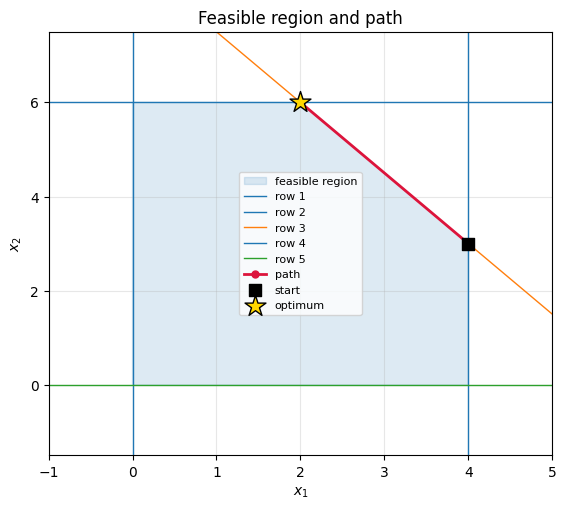

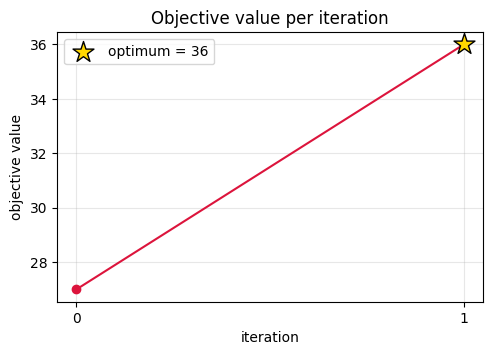

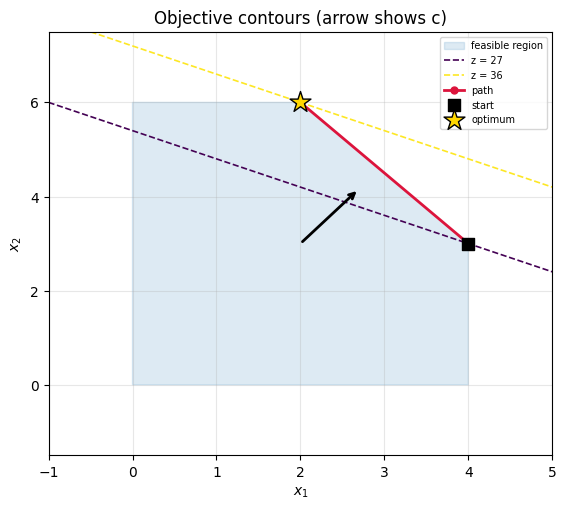

In [ ]:
#uncomment the show plots in this cell to make them visible, can be commented because not relavant to the algorithm
#and is not accurate representation for higher dimensional graphs
def vertices_2d(A, b):
    pts = []
    for i, j in itertools.combinations(range(A.shape[0]), 2):
        if numerical_rank(A[[i, j]]) < 2:
            continue
        p = np.linalg.solve(A[[i, j]], b[[i, j]])
        if is_feasible(A, b, p):
            pts.append(p)
    return pts


def clip(poly, a, beta):
    """Cut a convex polygon with the half-plane a.x <= beta."""
    out = []
    for k in range(len(poly)):
        P, Q = poly[k], poly[(k + 1) % len(poly)]
        fp, fq = a @ P - beta, a @ Q - beta
        if fp <= 0:
            out.append(P)
        if fp * fq < 0:
            out.append(P + fp / (fp - fq) * (Q - P))
    return np.array(out)


def window_and_region(A, b, res):
    pts = np.array(vertices_2d(A, b) + [p["x"] for p in res.path])
    lo, hi = pts.min(axis=0), pts.max(axis=0)
    span = np.maximum(hi - lo, 1.0)
    if res.status == "unbounded":
        end = res.x + res.ray * span.max()
        lo, hi = np.minimum(lo, end), np.maximum(hi, end)
        span = np.maximum(hi - lo, 1.0)
    lo, hi = lo - 0.25 * span, hi + 0.25 * span
    poly = np.array([[lo[0], lo[1]], [hi[0], lo[1]], [hi[0], hi[1]], [lo[0], hi[1]]])
    for a, beta in zip(A, b):
        if len(poly):
            poly = clip(poly, a, beta)
    return lo, hi, poly


def draw_region(ax, A, b, lo, hi, poly, lines=True):
    if len(poly) > 2:
        ax.fill(poly[:, 0], poly[:, 1], color="tab:blue", alpha=0.15, label="feasible region")
    if lines:
        xs = np.array([lo[0], hi[0]])
        for i, (a, beta) in enumerate(zip(A, b)):
            lab = f"row {i + 1}" if len(b) <= 8 else None
            if abs(a[1]) > 1e-12:
                ax.plot(xs, (beta - a[0] * xs) / a[1], lw=1, label=lab)
            else:
                ax.axvline(beta / a[0], lw=1, label=lab)
    ax.set_xlim(lo[0], hi[0])
    ax.set_ylim(lo[1], hi[1])
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.grid(alpha=0.3)


def draw_path(ax, res):
    P = np.array([p["x"] for p in res.path])
    ax.plot(P[:, 0], P[:, 1], "-o", color="crimson", lw=2, ms=5, label="path", zorder=3)
    ax.scatter(*res.start, marker="s", s=80, color="black", zorder=4, label="start")
    if res.status == "optimal":
        ax.scatter(*res.x, marker="*", s=250, color="gold", edgecolor="black", zorder=5, label="optimum")
    if res.status == "unbounded":
        w = ax.get_xlim()[1] - ax.get_xlim()[0]
        ax.annotate("", xy=res.x + 0.3 * w * res.ray, xytext=res.x,
                    arrowprops=dict(arrowstyle="->", color="green", lw=2))
        ax.plot([], [], color="green", label="improving ray")


def plot_region(A, b, res):
    lo, hi, poly = window_and_region(A, b, res)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    draw_region(ax, A, b, lo, hi, poly)
    draw_path(ax, res)
    ax.set_title("Feasible region and path")
    ax.legend(fontsize=8)
    plt.show()


def plot_objective(res):
    its = [p["iter"] for p in res.path]
    zs = [p["z"] for p in res.path]
    fig, ax = plt.subplots(figsize=(5.5, 3.5))
    ax.plot(its, zs, "-o", color="crimson")
    if res.status == "optimal":
        ax.scatter(its[-1], zs[-1], marker="*", s=250, color="gold", edgecolor="black",
                   zorder=5, label=f"optimum = {zs[-1]:.6g}")
        ax.legend()
    ax.set_xticks(its)
    ax.set_xlabel("iteration")
    ax.set_ylabel("objective value")
    ax.set_title("Objective value per iteration")
    ax.grid(alpha=0.3)
    plt.show()


def plot_contours(A, b, c, res):
    if np.linalg.norm(c) == 0:
        return
    lo, hi, poly = window_and_region(A, b, res)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    draw_region(ax, A, b, lo, hi, poly, lines=False)
    xs = np.array([lo[0], hi[0]])
    levels = sorted({round(p["z"], 9) for p in res.path})
    colors = plt.get_cmap("viridis")(np.linspace(0, 1, len(levels)))
    for lev, col in zip(levels, colors):
        if abs(c[1]) > 1e-12:
            ax.plot(xs, (lev - c[0] * xs) / c[1], "--", color=col, lw=1.2, label=f"z = {lev:.4g}")
        else:
            ax.axvline(lev / c[0], ls="--", color=col, lw=1.2, label=f"z = {lev:.4g}")
    draw_path(ax, res)
    mid = (lo + hi) / 2
    ax.annotate("", xy=mid + 0.15 * (hi - lo).max() * c / np.linalg.norm(c), xytext=mid,
                arrowprops=dict(arrowstyle="->", lw=2))
    ax.set_title("Objective contours (arrow shows c)")
    ax.legend(fontsize=7)
    plt.show()


def make_plots(c, A, b, res):
    if res is None or res.status in ("infeasible", "undetermined") or not res.path:
        print("Nothing to plot.")
        return
    if A.shape[1] == 2:
        plot_region(A, b, res)
        plot_objective(res)
        plot_contours(A, b, c, res)
    else:
        print(f"n = {A.shape[1]}: region plot needs n = 2, showing the objective plot only.")
        plot_objective(res)
#plot results
if result is not None:
   make_plots(c, A, b, result)

## 9. Tests

Each test checks
- the status
- every visited vertex is feasible with tight rank `n`
- the objective never decreases
- the objective value against a value worked out by hand
- the result against `scipy.optimize.linprog`

SciPy is used only for checking. The method above does not call it.

In [ ]:
SCIPY = {0: "optimal", 2: "infeasible", 3: "unbounded"}
summary = []


def check(name, c, A, b, status, z=None, start=None, degenerate=False):
    c, A, b = (np.asarray(v, float) for v in (c, A, b))
    res = solve_lp(c, A, b, start)
    assert res.status == status, f"{name}: got {res.status}, expected {status}"

    zs = [p["z"] for p in res.path]
    assert all(is_vertex(A, b, p["x"]) for p in res.path), f"{name}: visited point is not a vertex"
    assert all(b2 >= a2 - 1e-9 for a2, b2 in zip(zs, zs[1:])), f"{name}: objective decreased"
    if degenerate:
        assert any(len(p["tight"]) > A.shape[1] for p in res.path), f"{name}: no degenerate vertex"

    if status == "optimal":
        assert abs(res.z - z) < 1e-6, f"{name}: z = {res.z}, expected {z}"
    if status == "unbounded":
        assert c @ res.ray > 0 and np.all(A @ res.ray <= 1e-7), f"{name}: bad ray"

    ref = linprog(-c, A_ub=A, b_ub=b, bounds=[(None, None)] * A.shape[1], method="highs")
    assert SCIPY.get(ref.status) == status, f"{name}: SciPy says {SCIPY.get(ref.status)}"
    if status == "optimal":
        assert abs(-ref.fun - res.z) < 1e-6 * (1 + abs(res.z)), f"{name}: differs from SciPy"

    summary.append((name, status, "-" if res.z is None or status != "optimal" else f"{res.z:.6g}",
                    fmt(res.x) if status == "optimal" else "-", len(res.path)))
    return res


def show_summary():
    print(f"{'test':<36}{'status':<12}{'z':<10}{'vertex':<26}{'vertices'}")
    for name, st, z, x, k in summary:
        print(f"{name:<36}{st:<12}{z:<10}{x:<26}{k}")
    print(f"\nAll {len(summary)} tests passed.")

### Test 1: unique optimum
- max `3x1 + 5x2`, constraints as in the sample file
- Vertices `(0,0) (4,0) (4,3) (2,6) (0,6)` give `z = 0, 12, 27, 36, 30`
- Expected: `(2, 6)`, `z = 36`

In [ ]:
A1 = [[1, 0], [0, 2], [3, 2], [-1, 0], [0, -1]]
b1 = [4, 12, 18, 0, 0]
check("1 unique optimum", [3, 5], A1, b1, "optimal", 36, start=[0, 0]);

### Test 2: multiple optima
- max `x1 + x2`, `x1 + x2 <= 4`, `x1 <= 3`, `x2 <= 3`, `x1, x2 >= 0`
- The whole edge from `(3,1)` to `(1,3)` is optimal
- Expected: `z = 4`

In [ ]:
check("2 multiple optima", [1, 1], [[1, 1], [1, 0], [0, 1], [-1, 0], [0, -1]], [4, 3, 3, 0, 0],
      "optimal", 4, start=[0, 0]);

### Test 3: infeasible
- `x1 <= 1` and `x1 >= 2` cannot both hold
- Expected: no feasible solution

In [ ]:
check("3 infeasible", [1, 1], [[1, 0], [-1, 0], [0, 1], [0, -1]], [1, -2, 1, 0], "infeasible");

### Test 4: unbounded
- max `x1 + x2`, `x1, x2 >= 0`, `x1 - x2 <= 1`
- From `(0,0)`, direction `(0,1)` stays feasible and increases `z`
- Expected: unbounded

In [ ]:
res4 = check("4 unbounded", [1, 1], [[-1, 0], [0, -1], [1, -1]], [0, 0, 1], "unbounded")
report(res4, np.array([1.0, 1.0]), np.array([[-1, 0], [0, -1], [1, -1.0]]), np.array([0, 0, 1.0]))

Initial vertex
  x        = [0, 0]
  z        = 0
  feasible = True

Vertices visited
  iter vertex                z           tight rows
  0    [0, 0]                0           [1, 2]

Result
  Objective function is not bounded.
  Improving ray from [0, 0] along [0, 1]


### Test 5: degenerate vertex
- **5a:** max `2x1 + x2`, `x1 <= 2`, `x2 <= 2`, `x1 + x2 <= 4`, `x1, x2 >= 0`
  - Three constraints are tight at `(2,2)`, expected `z = 6`
- **5b, 5c:** 3 variables, `x >= 0`, `x1 + x3 <= 1`, `x2 + x3 <= 1`
  - Four constraints are tight at `(0,0,1)`, and we start there
  - `c = (0,0,1)`: already optimal, `z = 1`
  - `c = (1,1,0)`: optimum `(1,1,0)`, `z = 2`

In [ ]:
check("5a degenerate, 2D", [2, 1], [[1, 0], [0, 1], [1, 1], [-1, 0], [0, -1]], [2, 2, 4, 0, 0],
      "optimal", 6, start=[0, 0], degenerate=True)

A5 = [[-1, 0, 0], [0, -1, 0], [0, 0, -1], [1, 0, 1], [0, 1, 1]]
b5 = [0, 0, 0, 1, 1]
check("5b degenerate, 3D, c=(0,0,1)", [0, 0, 1], A5, b5, "optimal", 1, start=[0, 0, 1], degenerate=True)
check("5c degenerate, 3D, c=(1,1,0)", [1, 1, 0], A5, b5, "optimal", 2, start=[0, 0, 1], degenerate=True);

### Test 6: redundant constraints
- max `x1 + x2`, `x1 <= 2`, `x2 <= 2`, `x1 + x2 <= 10`, `2x1 <= 4`, `x1, x2 >= 0`
- `x1 + x2 <= 10` is never active and `2x1 <= 4` repeats `x1 <= 2`
- Expected: `(2, 2)`, `z = 4`

In [ ]:
check("6 redundant rows", [1, 1], [[1, 0], [0, 1], [1, 1], [2, 0], [-1, 0], [0, -1]],
      [2, 2, 10, 4, 0, 0], "optimal", 4, start=[0, 0]);

### Test 7: negative coefficients and right-hand sides
- min `x1 + 2x2`, which is max `-x1 - 2x2`
- `x1 >= -1`, `x2 >= 1`, `x1 + x2 >= 3`, `x1 <= 4`, `x2 <= 4`
- Vertices `(-1,4) (2,1) (4,1) (4,4)` give `x1 + 2x2 = 7, 4, 6, 12`
- Expected: `(2, 1)`, `z = -4`

In [ ]:
check("7 negative data", [-1, -2], [[-1, 0], [0, -1], [-1, -1], [1, 0], [0, 1]], [1, -1, -3, 4, 4],
      "optimal", -4);

### Test 8: more than two variables
- max `4x1 + 3x2 + 2x3 + x4`, `0 <= xi <= 1`, `x1 + x2 + x3 + x4 <= 2.5`
- Fill the largest coefficients first: `x = (1, 1, 0.5, 0)`
- Expected: `z = 4 + 3 + 1 = 8`
- Then 40 random bounded problems (2 to 4 variables) are compared with SciPy

In [ ]:
A8 = np.vstack([-np.eye(4), np.eye(4), np.ones((1, 4))])
b8 = np.concatenate([np.zeros(4), np.ones(4), [2.5]])
res8 = check("8 four variables", [4, 3, 2, 1], A8, b8, "optimal", 8)

rng = np.random.default_rng(12345)
for k in range(40):
    n_r = int(rng.integers(2, 5))
    A_r = np.vstack([rng.normal(size=(int(rng.integers(3, 7)), n_r)), np.eye(n_r), -np.eye(n_r)])
    b_r = np.concatenate([rng.uniform(1, 5, size=A_r.shape[0] - 2 * n_r), 5 * np.ones(2 * n_r)])
    c_r = rng.normal(size=n_r)
    r = solve_lp(c_r, A_r, b_r)
    ref = linprog(-c_r, A_ub=A_r, b_ub=b_r, bounds=[(None, None)] * n_r, method="highs")
    assert r.status == "optimal" and ref.status == 0
    assert is_vertex(A_r, b_r, r.x) and abs(r.z + ref.fun) < 1e-6 * (1 + abs(r.z)), f"random test {k} failed"
summary.append(("8b 40 random problems vs SciPy", "optimal", "-", "-", "-"))

### Test 9: numerical edge cases
- **9a:** `x1 <= 1`, `x2 <= 1`, `x1 + x2 <= 2 + 1e-11`, `x1, x2 >= 0`
  - The third constraint is tight within tolerance at `(1,1)`
  - Expected: `z = 2`
- **9b:** `x1 <= 1e-10`, `x2 <= 1`, `x1, x2 >= 0`
  - The first step is almost zero in length
  - Expected: `z = 1`

In [ ]:
check("9a nearly tight constraint", [1, 1], [[1, 0], [0, 1], [1, 1], [-1, 0], [0, -1]],
      [1, 1, 2 + 1e-11, 0, 0], "optimal", 2, start=[0, 0])
check("9b tiny step", [1, 1], [[1, 0], [0, 1], [-1, 0], [0, -1]], [1e-10, 1, 0, 0], "optimal", 1);

### Summary of tests

In [ ]:
show_summary()

test                                status      z         vertex                    vertices
1 unique optimum                    optimal     36        [2, 6]                    3
2 multiple optima                   optimal     4         [1, 3]                    3
3 infeasible                        infeasible  -         -                         0
4 unbounded                         unbounded   -         -                         1
5a degenerate, 2D                   optimal     6         [2, 2]                    3
5b degenerate, 3D, c=(0,0,1)        optimal     1         [0, 0, 1]                 1
5c degenerate, 3D, c=(1,1,0)        optimal     2         [1, 1, 0]                 2
6 redundant rows                    optimal     4         [2, 2]                    3
7 negative data                     optimal     -4        [2, 1]                    2
8 four variables                    optimal     8         [1, 1, 0.5, 0]            4
8b 40 random problems vs SciPy      optimal    

## 10. Complexity and limitations

**Initial vertex**
- Up to `C(m, n)` subsets, each needs a rank check and a solve (`O(n^3)`) plus a feasibility check (`O(mn)`)
- Grows exponentially, fine only for small inputs

**One iteration**
- `k` tight rows give up to `C(k, n-1)` subsets, each with an SVD (`O(n^3)`)
- Non-degenerate vertex: `k = n`, so about `n` subsets
- Highly degenerate vertex: many more subsets
- Ratio test: `O(mn)` per direction

**Number of iterations**
- The objective strictly increases, so no vertex is repeated
- The number of vertices can be exponential, so there is no polynomial worst-case bound
- In practice few vertices are visited

**Limitations**
- Only `max c^T x, A x <= b` with `rank(A) = n`
- Tolerances decide what counts as tight, feasible or dependent
- Badly scaled data may end in `numerical_failure` or `cycle`, which is reported
- Only one optimal vertex is returned
- Feasibility is checked by enumeration, which can be slow

**Conclusion**
- The method moves vertex to vertex using tight rows, rank, null-space edge directions and the ratio test
- It detects infeasible, unbounded and optimal cases
- All tests agree with hand calculations and SciPy